# Notebook 03 — DNN Hyperparameter Tuning & Class Imbalance

**Goal:** Improve our mid-course DNN (G1 and G2 included) and check whether class weights help identify Low-performing students.

**We will:** Reuse the 12 features from Notebook 01, reproduce Notebook 02's split and preprocessing, compare six controlled configurations, and save the best *validation-selected* model.

**We will NOT:** Train on validation/test data, use SMOTE, or inspect the reserved 130-row test set. Validation results are development results, not final test results.


## 1. Imports and reproducibility

Run from `notebooks/`. Install missing dependencies in your terminal:

`python -m pip install tensorflow scikit-learn pandas numpy matplotlib joblib`


In [1]:
from pathlib import Path
import json
import random
import gc

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score, recall_score, classification_report, ConfusionMatrixDisplay
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

DATA_PATH = Path("../data/student-por.csv")
FEATURE_PATH = Path("../models/selected_features.json")
MODELS_DIR = Path("../models")
assert DATA_PATH.exists(), f"Missing {DATA_PATH}"
assert FEATURE_PATH.exists(), "Run Notebook 01 first."
MODELS_DIR.mkdir(exist_ok=True, parents=True)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 2. Load the selected features and recreate the same split

**Why?** Every experiment must use exactly the same students and features. `G3` defines the target but must never be a model input.

In [2]:
df = pd.read_csv(DATA_PATH, sep=";")
feature_config = json.loads(FEATURE_PATH.read_text(encoding="utf-8"))
features = feature_config["selected_features"]

def category(g3):
    if g3 < 10: return "Low"
    if g3 < 14: return "Average"
    return "Good"

X = df[features].copy()
y = df["G3"].map(category)
assert len(features) == 12 and {"G1", "G2"}.issubset(features)
assert "G3" not in features and not X.isna().any().any()

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.20, random_state=SEED, stratify=y_dev
)
print("Train:", len(X_train), "| Validation:", len(X_val), "| Reserved test:", len(X_test))
print("Training categories:")
display(y_train.value_counts().reindex(["Low", "Average", "Good"]).to_frame("students"))
# Do not inspect X_test or y_test until the final evaluation notebook.


Train: 415 | Validation: 104 | Reserved test: 130
Training categories:


,students
G3,
Low,64
Average,227
Good,124


## 3. Training-only preprocessing

**Henglish:** Numerical columns ko scale karenge; categorical columns ko one-hot encode karenge. Preprocessor **sirf training data par fit** hoga. Validation par sirf transform hoga.

In [3]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object", "category"]).columns.tolist()
try:
    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    ohe = OneHotEncoder(handle_unknown="ignore", sparse=False)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", ohe, categorical_features)
])
X_train_p = preprocessor.fit_transform(X_train).astype("float32")
X_val_p = preprocessor.transform(X_val).astype("float32")

label_encoder = LabelEncoder()
y_train_e = label_encoder.fit_transform(y_train)
y_val_e = label_encoder.transform(y_val)
print("Input neurons:", X_train_p.shape[1])
print("Class mapping:", dict(enumerate(label_encoder.classes_)))

Input neurons: 18
Class mapping: {0: 'Average', 1: 'Good', 2: 'Low'}


## 4. Understand and calculate class weights

The dataset has more **Average** than **Low** students. Balanced class weights assign larger penalties to errors on underrepresented classes.

Formula: `weight(class) = number_of_training_samples / (number_of_classes × samples_in_class)`.

**Important:** We calculate weights using **training labels only**. Class weighting may improve Low recall but can reduce precision or accuracy. We will compare both approaches rather than assume an improvement.

In [4]:
classes = np.unique(y_train_e)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_e
)
class_weights = {int(cls): float(w) for cls, w in zip(classes, weights)}
display(pd.DataFrame({
    "category": label_encoder.inverse_transform(classes),
    "training_count": [(y_train_e == c).sum() for c in classes],
    "class_weight": weights
}))
print("Class weight mapping:", class_weights)

,category,training_count,class_weight
0,Average,227,0.609398
1,Good,124,1.115591
2,Low,64,2.161458


Class weight mapping: {0: 0.6093979441997063, 1: 1.1155913978494623, 2: 2.1614583333333335}


## 5. Define the DNN and a small, controlled search

We keep the architecture simple: `Input → Dense(64, ReLU) → Dropout → Dense(32, ReLU) → Dropout → Dense(3, Softmax)`.

We test six configurations, changing learning rate, dropout, and whether balanced class weights are used. **This is a small manual hyperparameter search**, not an exhaustive search.

For a fair comparison, we reset the random seed before each run. Early stopping uses validation loss; final configuration selection uses validation macro F1, then Low recall, then accuracy as tie-breakers.

In [5]:
def build_dnn(input_dim, learning_rate, dropout):
    model = Sequential([
        Input(shape=(input_dim,)),
        Dense(64, activation="relu"),
        Dropout(dropout),
        Dense(32, activation="relu"),
        Dropout(dropout),
        Dense(3, activation="softmax")
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

experiments = [
    {"name": "A_baseline",       "learning_rate": 0.001,  "dropout": 0.2, "weighted": False},
    {"name": "B_weighted",       "learning_rate": 0.001,  "dropout": 0.2, "weighted": True},
    {"name": "C_low_lr",         "learning_rate": 0.0005, "dropout": 0.2, "weighted": False},
    {"name": "D_low_lr_weighted","learning_rate": 0.0005, "dropout": 0.2, "weighted": True},
    {"name": "E_high_dropout",   "learning_rate": 0.001,  "dropout": 0.3, "weighted": False},
    {"name": "F_dropout_weighted","learning_rate":0.001, "dropout": 0.3, "weighted": True},
]
display(pd.DataFrame(experiments))

,name,learning_rate,dropout,weighted
0,A_baseline,0.0010,0.2,False
1,B_weighted,0.0010,0.2,True
2,C_low_lr,0.0005,0.2,False
3,D_low_lr_weighted,0.0005,0.2,True
4,E_high_dropout,0.0010,0.3,False
5,F_dropout_weighted,0.0010,0.3,True


## 6. Train and compare configurations

**Metrics:**
- **Accuracy:** Overall fraction correct.
- **Macro F1:** Each class counts equally, helpful for imbalance.
- **Low recall:** Fraction of actual Low students identified.

We save the best model *as we go* to avoid keeping six neural networks in memory. If scores tie, we prefer higher Low recall and then accuracy. These are **validation** metrics; repeated comparison on one small validation set can overfit model selection.

In [6]:
results = []
histories = {}
best_score = (-1.0, -1.0, -1.0)
best_name = None
best_params = None

for exp in experiments:
    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(SEED)
    model = build_dnn(
        X_train_p.shape[1],
        learning_rate=exp["learning_rate"],
        dropout=exp["dropout"]
    )
    stopper = EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    )
    history = model.fit(
        X_train_p, y_train_e,
        validation_data=(X_val_p, y_val_e),
        epochs=100,
        batch_size=32,
        class_weight=class_weights if exp["weighted"] else None,
        callbacks=[stopper],
        verbose=0
    )
    pred_ids = np.argmax(model.predict(X_val_p, verbose=0), axis=1)
    pred_labels = label_encoder.inverse_transform(pred_ids)

    accuracy = accuracy_score(y_val, pred_labels)
    macro_f1 = f1_score(y_val, pred_labels, average="macro", zero_division=0)
    low_recall = recall_score(
        y_val, pred_labels, labels=["Low"], average="macro", zero_division=0
    )
    result = {**exp, "epochs": len(history.history["loss"]),
              "val_accuracy": float(accuracy),
              "val_macro_f1": float(macro_f1),
              "val_low_recall": float(low_recall)}
    results.append(result)
    histories[exp["name"]] = {
        key: [float(v) for v in values]
        for key, values in history.history.items()
    }
    print(f'{exp["name"]:<20} accuracy={accuracy:.2%} | macro F1={macro_f1:.2%} | Low recall={low_recall:.2%}')

    score = (float(macro_f1), float(low_recall), float(accuracy))
    if score > best_score:
        best_score = score
        best_name = exp["name"]
        best_params = exp.copy()
        model.save(MODELS_DIR / "tuned_dnn.keras")

    del model

results_df = pd.DataFrame(results).sort_values(
    ["val_macro_f1", "val_low_recall", "val_accuracy"],
    ascending=False
).reset_index(drop=True)
print("\nBest validation-selected configuration:", best_name)
display(results_df)


A_baseline           accuracy=84.62% | macro F1=81.68% | Low recall=68.75%
B_weighted           accuracy=78.85% | macro F1=77.37% | Low recall=81.25%
C_low_lr             accuracy=84.62% | macro F1=80.84% | Low recall=62.50%
D_low_lr_weighted    accuracy=77.88% | macro F1=76.40% | Low recall=81.25%
E_high_dropout       accuracy=84.62% | macro F1=81.48% | Low recall=68.75%
F_dropout_weighted   accuracy=78.85% | macro F1=77.10% | Low recall=81.25%

Best validation-selected configuration: A_baseline


,name,learning_rate,dropout,weighted,epochs,val_accuracy,val_macro_f1,val_low_recall
0,A_baseline,0.0010,0.2,False,44,0.846154,0.816792,0.6875
1,E_high_dropout,0.0010,0.3,False,49,0.846154,0.814783,0.6875
2,C_low_lr,0.0005,0.2,False,76,0.846154,0.808421,0.6250
3,B_weighted,0.0010,0.2,True,65,0.788462,0.773719,0.8125
4,F_dropout_weighted,0.0010,0.3,True,52,0.788462,0.771034,0.8125
5,D_low_lr_weighted,0.0005,0.2,True,100,0.778846,0.763962,0.8125


## 7. Visualize the comparison

Compare the configurations, especially **macro F1** and **Low recall**. High overall accuracy alone is not enough.

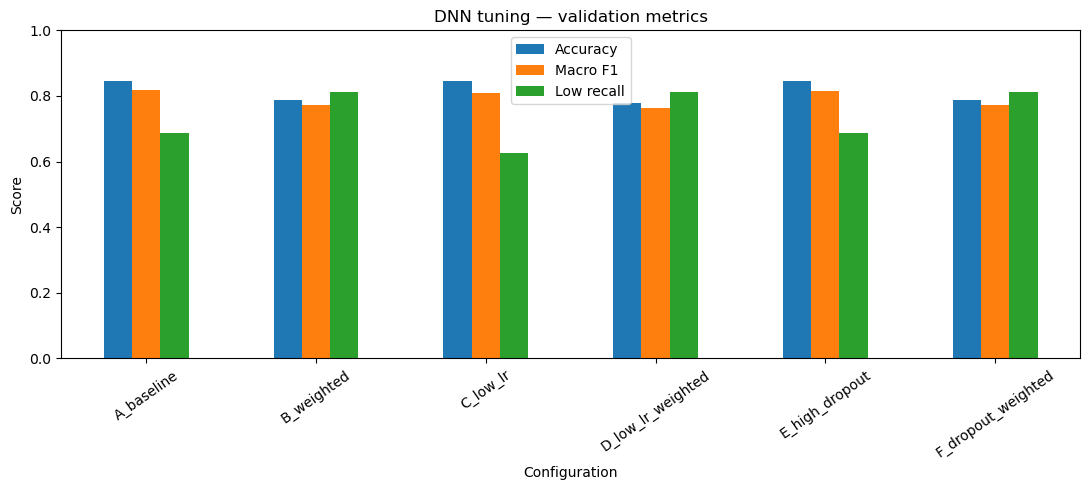

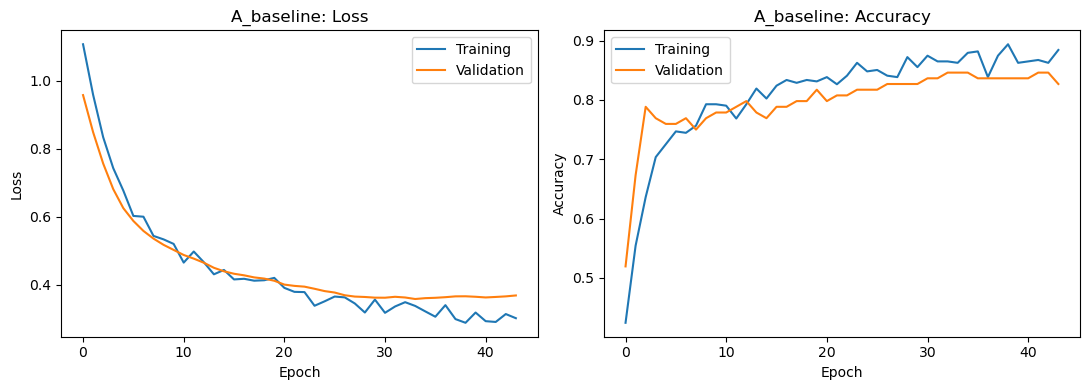

In [7]:
plot_df = pd.DataFrame(results).set_index("name")
ax = plot_df[["val_accuracy", "val_macro_f1", "val_low_recall"]].plot(
    kind="bar", figsize=(11, 5)
)
ax.set(title="DNN tuning — validation metrics", xlabel="Configuration",
       ylabel="Score", ylim=(0, 1))
ax.tick_params(axis="x", rotation=35)
ax.legend(["Accuracy", "Macro F1", "Low recall"])
plt.tight_layout()
plt.show()

h = histories[best_name]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(h["loss"], label="Training")
axes[0].plot(h["val_loss"], label="Validation")
axes[0].set(title=f"{best_name}: Loss", xlabel="Epoch", ylabel="Loss")
axes[0].legend()
axes[1].plot(h["accuracy"], label="Training")
axes[1].plot(h["val_accuracy"], label="Validation")
axes[1].set(title=f"{best_name}: Accuracy", xlabel="Epoch", ylabel="Accuracy")
axes[1].legend()
plt.tight_layout()
plt.show()

## 8. Inspect the selected model's validation predictions

This helps us see whether Low students are still being misclassified. **These are not test results.**

Selected: A_baseline
              precision    recall  f1-score   support

         Low       0.69      0.69      0.69        16
     Average       0.86      0.86      0.86        57
        Good       0.90      0.90      0.90        31

    accuracy                           0.85       104
   macro avg       0.82      0.82      0.82       104
weighted avg       0.85      0.85      0.85       104



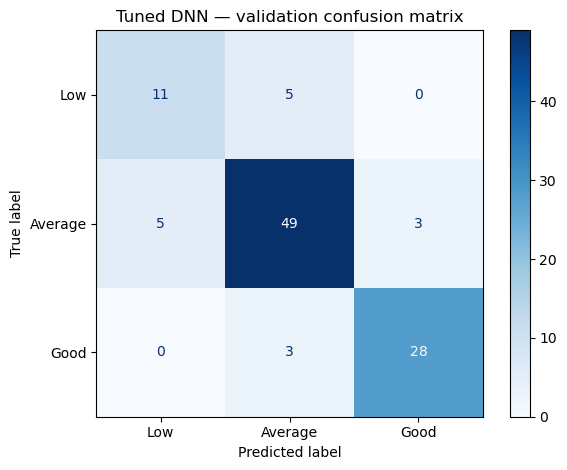

In [8]:
best_model = tf.keras.models.load_model(MODELS_DIR / "tuned_dnn.keras")
best_probabilities = best_model.predict(X_val_p, verbose=0)
best_pred = label_encoder.inverse_transform(np.argmax(best_probabilities, axis=1))

print("Selected:", best_name)
print(classification_report(
    y_val, best_pred, labels=["Low", "Average", "Good"], zero_division=0
))
ConfusionMatrixDisplay.from_predictions(
    y_val, best_pred, labels=["Low", "Average", "Good"],
    cmap="Blues", values_format="d"
)
plt.title("Tuned DNN — validation confusion matrix")
plt.tight_layout()
plt.show()

## 9. Save artifacts for the next notebooks

We save:
- `tuned_dnn.keras` — validation-selected DNN.
- `tuned_dnn_preprocessor.joblib` — train-fitted preprocessing.
- `tuned_dnn_label_encoder.joblib` — category mapping.
- `tuned_dnn_metadata.json` — selected parameters and validation results.
- `dnn_tuning_results.csv` — comparison table.

These are **development artifacts**. Do not call the model final or report independent test performance yet.

Only load `.joblib` files that you created yourself and trust.

In [9]:
joblib.dump(preprocessor, MODELS_DIR / "tuned_dnn_preprocessor.joblib")
joblib.dump(label_encoder, MODELS_DIR / "tuned_dnn_label_encoder.joblib")
results_df.to_csv(MODELS_DIR / "dnn_tuning_results.csv", index=False)

selected_result = next(r for r in results if r["name"] == best_name)
metadata = {
    "stage": "validation_selected_dnn",
    "prediction_stage": "after_G2",
    "selected_features": features,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "class_names": label_encoder.classes_.tolist(),
    "seed": SEED,
    "selection_rule": "max_validation_macro_f1_then_low_recall_then_accuracy",
    "selected_configuration": selected_result,
    "all_experiments": results,
    "test_set_evaluated": False
}
(MODELS_DIR / "tuned_dnn_metadata.json").write_text(
    json.dumps(metadata, indent=2), encoding="utf-8"
)

loaded_preprocessor = joblib.load(MODELS_DIR / "tuned_dnn_preprocessor.joblib")
loaded_encoder = joblib.load(MODELS_DIR / "tuned_dnn_label_encoder.joblib")
loaded_model = tf.keras.models.load_model(MODELS_DIR / "tuned_dnn.keras")
reloaded_prob = loaded_model.predict(
    loaded_preprocessor.transform(X_val).astype("float32"), verbose=0
)
np.testing.assert_allclose(reloaded_prob, best_probabilities, atol=1e-6, rtol=1e-5)
assert loaded_encoder.classes_.tolist() == label_encoder.classes_.tolist()
print("PASS — Tuned model and preprocessing reload correctly.")
print("Selected configuration:", best_name)
print("Next: Notebook 04 — Logistic Regression and Random Forest comparison.")

PASS — Tuned model and preprocessing reload correctly.
Selected configuration: A_baseline
Next: Notebook 04 — Logistic Regression and Random Forest comparison.


## Viva-ready explanation

> My dataset contains fewer Low-performing students than Average students. I therefore compared DNN configurations with and without balanced class weights, alongside different learning rates and dropout settings. I calculated weights using only training labels and selected the configuration using validation macro F1, with Low recall and accuracy as tie-breakers. I kept the independent test set reserved for final evaluation.

**Important:** Class weighting is an experiment, not a guaranteed improvement. A 104-student validation set contains relatively few Low cases, so we should not overinterpret small metric differences.

### Next
Notebook 04 will train **Logistic Regression and Random Forest** on the same selected features and splits, and compare their **validation** metrics with the tuned DNN.
